# QuickDraw preprocessing for the recurrent classifier

This notebook contains the complete preprocessing workflow: inspect the downloaded
archives, fit coordinate scaling on training data, prepare all categories, and
inspect batches. No VAE or stroke reconstruction loss is required for the first
cross-entropy classification baseline.

The entire official **Sketch-RNN collection** can be downloaded by the cell below to `data/sketchrnn/`:
345 standard `.npz` files and 345 `.full.npz` files. This is the vector dataset
chosen for this project; raw NDJSON and bitmap exports are different versions.

Standard files have 70,000 train / 2,500 valid / 2,500 test sketches per category.
The `.full.npz` files offer more training examples. **Choose one version, never
concatenate both versions.** Preserve each archive's existing split membership.

Source: [Google QuickDraw dataset](https://github.com/googlecreativelab/quickdraw-dataset#sketch-rnn-quickdraw-dataset).
Attribution: Google, Inc., CC BY 4.0.

The four-step top-left / 255 / 1-pixel / RDP pipeline in Google's README
is documented for simplified NDJSON. Sketch-RNN archives already contain
processed stroke sequences. We add uniform per-sketch scaling to a longest
bounding-box dimension of 1, followed by training-derived numerical scaling.
We do not add geometric alignment, resampling, or another RDP pass.

In [1]:
from pathlib import Path
import json
import math  # Included with Python; no pip installation needed.
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm import tqdm

# Find the repository even on a fresh clone with no downloaded data yet.
cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents)
             if (p / "requirements.txt").is_file() and (p / "data_preprocessing").is_dir()), None)
assert ROOT is not None, "Launch from this repository or data_preprocessing folder"
DATA = ROOT / "data"
SOURCE = DATA / "sketchrnn"
SOURCE.mkdir(parents=True, exist_ok=True)

USE_FULL = True
DOWNLOAD_BOTH_VERSIONS = True  # Entire collection: 690 files, approximately 10.1 GiB.
VERIFY_EXISTING_DOWNLOADS = False  # True rechecks MD5; new downloads always get checked.
WORKERS = 4  # Reduce to 1 if memory is limited.
OUTPUT = DATA / ("processed_full" if USE_FULL else "processed_standard")
SPLITS = ("train", "valid", "test")
PREPROCESSING_VERSION = 2
PER_SKETCH_SCALING = {"method": "max_bbox_dimension", "target": 1.0, "degenerate": "identity"}
manifest_path = OUTPUT / "manifest.json"
existing = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
REBUILD = existing.get("preprocessing_version") != PREPROCESSING_VERSION or existing.get("per_sketch_scaling") != PER_SKETCH_SCALING
# Set REBUILD=True manually to force regeneration of matching prepared outputs.
print("Repository:", ROOT)
print("PyTorch:", torch.__version__, "CUDA available:", torch.cuda.is_available())

Repository: C:\Users\shrua\OneDrive\Desktop\11785 IDL\vector-sketch-classification
PyTorch: 2.11.0+cu128 CUDA available: True


## Download the dataset (first run on each teammate's machine)
Run this cell before processing. It reads the official public bucket inventory,
downloads into `data/sketchrnn/`, and checks each new archive's size and MD5.
Existing files of the expected size are reused; set
`VERIFY_EXISTING_DOWNLOADS=True` to checksum them again.

`DOWNLOAD_BOTH_VERSIONS=True` downloads all 690 standard and full archives
(approximately 10.1 GiB). Set it to False to download only the version chosen
by `USE_FULL`. Downloads use temporary files and can be resumed by rerunning;
a failed individual download starts again. No Google account or Cloud SDK is
required. Data remains ignored by Git.

In [2]:
import base64
import hashlib
import shutil
import time
from urllib.parse import quote, urlencode
from urllib.request import urlopen

inventory_path = SOURCE / "download_manifest.json"
if inventory_path.exists():
    inventory = json.loads(inventory_path.read_text(encoding="utf-8"))
else:
    inventory = []
    page_token = None
    while True:
        query = {"prefix": "sketchrnn/", "maxResults": 1000}
        if page_token:
            query["pageToken"] = page_token
        url = "https://storage.googleapis.com/storage/v1/b/quickdraw_dataset/o?" + urlencode(query)
        with urlopen(url, timeout=120) as response:
            page = json.load(response)
        inventory.extend({"name": item["name"], "size": int(item["size"]), "md5Hash": item["md5Hash"]}
                         for item in page.get("items", []) if item["name"].endswith(".npz"))
        page_token = page.get("nextPageToken")
        if not page_token:
            break
    inventory_path.write_text(json.dumps(inventory, indent=2), encoding="utf-8")

selected_files = [item for item in inventory if DOWNLOAD_BOTH_VERSIONS
                  or item["name"].endswith(".full.npz") == USE_FULL]
assert len(selected_files) == (690 if DOWNLOAD_BOTH_VERSIONS else 345)

def file_md5(path):
    digest = hashlib.md5()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return base64.b64encode(digest.digest()).decode()

def download_archive(item):
    path = SOURCE / Path(item["name"]).name
    if path.exists() and path.stat().st_size == item["size"]:
        if not VERIFY_EXISTING_DOWNLOADS or file_md5(path) == item["md5Hash"]:
            return
    temporary = path.with_suffix(".npz.part")
    for attempt in range(3):
        try:
            url = "https://storage.googleapis.com/quickdraw_dataset/" + quote(item["name"])
            with urlopen(url, timeout=180) as response, temporary.open("wb") as stream:
                shutil.copyfileobj(response, stream)
            if temporary.stat().st_size != item["size"] or file_md5(temporary) != item["md5Hash"]:
                raise ValueError(f"Download checksum mismatch: {path.name}")
            temporary.replace(path)
            return
        except Exception:
            if attempt == 2:
                raise
            time.sleep(2)
        finally:
            temporary.unlink(missing_ok=True)

with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    futures = [pool.submit(download_archive, item) for item in selected_files]
    for future in tqdm(as_completed(futures), total=len(futures), desc="Download / reuse"):
        future.result()

categories = sorted(Path(item["name"]).name.removesuffix(".npz")
                    for item in inventory if not item["name"].endswith(".full.npz"))
assert len(categories) == 345
class_to_index = {name: index for index, name in enumerate(categories)}

def archive_path(category):
    return SOURCE / (category + (".full.npz" if USE_FULL else ".npz"))

assert all(archive_path(category).is_file() for category in categories)
print("Ready:", len(categories), "categories; version:", "full" if USE_FULL else "standard")

Download / reuse:   0%|          | 0/690 [00:00<?, ?it/s]

Download / reuse: 100%|██████████| 690/690 [00:00<00:00, 14259.66it/s]

Ready: 345 categories; version: full


## 1. Understand stroke-3 storage
Each sketch is an array `[T, 3]` containing `[dx, dy, pen_up]`. `pen_up=1`
ends the current stroke; the next movement repositions the pen to another
stroke. Sketch-RNN converts this storage format to stroke-5 for its generative
model, but our classifier can directly use stroke-3 with sequence lengths.

Only trusted official source archives are loaded with pickle enabled.
Prepared outputs below contain numeric/string arrays and do not need pickle.

Cat split counts: {'train': 106337, 'valid': 2500, 'test': 2500}


Sketch shape: (96, 3)
First points [dx, dy, pen_up]:
[[ -3.  -8.   0.]
 [  2. -38.   0.]
 [ 14.   8.   0.]
 [ 20.  26.   0.]
 [ 22. -14.   0.]
 [ 10.  -3.   0.]
 [ 51.   0.   0.]
 [ 31.  -5.   0.]]


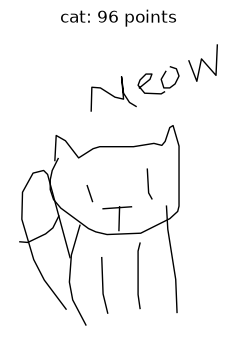

In [3]:
with np.load(archive_path("cat"), allow_pickle=True, encoding="latin1") as archive:
    print("Cat split counts:", {split: len(archive[split]) for split in SPLITS})
    example = np.asarray(archive["train"][0], dtype=np.float32)
print("Sketch shape:", example.shape)
print("First points [dx, dy, pen_up]:")
print(example[:8])

def draw_sketch(ax, sequence):
    xy = np.cumsum(sequence[:, :2], axis=0)
    start = 0
    for end in np.flatnonzero(sequence[:, 2] == 1):
        line = xy[start:end + 1]
        ax.plot(line[:, 0], line[:, 1], "k-", linewidth=1)
        start = end + 1
    if start < len(xy):
        ax.plot(xy[start:, 0], xy[start:, 1], "k-", linewidth=1)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")

fig, ax = plt.subplots(figsize=(4, 4))
draw_sketch(ax, example)
ax.set_title(f"cat: {len(example)} points")
plt.show()

## 2. Validate and pack sequences
We keep every sketch and every point. There is no class subsampling, length cap,
clipping, extra simplification, or augmentation. Invalid data raises an error
instead of silently changing the dataset.

Each worker handles one archive at a time (four workers by default). Flat point storage plus offsets avoids padding
the entire dataset or holding all categories in memory. Labels are integer class
indices. IDs encode category, source version, split, and original row index.

Before fitting numerical normalization, reconstruct each sketch's coordinates
and divide its dx/dy by the longer bounding-box dimension. The longest
dimension becomes 1, with aspect ratio and pen flags preserved. Degenerate
zero-size sketches are left unchanged. No translation or point removal is added.

In [4]:
def pack_sequences(sequences):
    if len(sequences) == 0:
        raise ValueError("Empty split")
    if any(s.ndim != 2 or s.shape[1] != 3 or len(s) == 0 for s in sequences):
        raise ValueError("Expected nonempty [T, 3] stroke sequences")
    lengths = np.fromiter((len(s) for s in sequences), dtype=np.int64, count=len(sequences))
    points = np.concatenate(sequences).astype(np.float32)
    if not np.isfinite(points).all():
        raise ValueError("Nonfinite coordinates")
    if not np.isin(points[:, 2], [0, 1]).all():
        raise ValueError("Pen flags must be 0 or 1")
    offsets = np.concatenate(([0], np.cumsum(lengths)))
    return points, offsets, lengths

points, offsets, lengths = pack_sequences([example, example[:5]])
assert np.array_equal(points[offsets[0]:offsets[1]], example)
assert offsets[-1] == len(points)
print("Packing verified:", points.shape, offsets.tolist())

def uniform_scale(points, offsets):
    """Scale each sketch's longest bounding-box dimension to 1; retain aspect ratio."""
    # Global cumulative positions differ from local positions only by a constant
    # per sketch; each sketch's bounding-box width/height is therefore identical.
    positions = np.cumsum(points[:, :2], axis=0, dtype=np.float64)
    lower = np.minimum.reduceat(positions, offsets[:-1], axis=0)
    upper = np.maximum.reduceat(positions, offsets[:-1], axis=0)
    dimensions = np.max(upper - lower, axis=1)
    divisors = np.where(dimensions > 0, dimensions, 1.0).astype(np.float32)
    scaled = points.copy()
    scaled[:, :2] /= np.repeat(divisors, np.diff(offsets))[:, None]
    return scaled

# Geometrically identical sketches of different sizes should become identical.
a = np.array([[0, 0, 0], [100, 0, 0], [0, 50, 1]], dtype=np.float32)
b = a.copy()
b[:, :2] *= 2
packed, boundaries, _ = pack_sequences([a, b, np.array([[0, 0, 1]], dtype=np.float32)])
scaled = uniform_scale(packed, boundaries)
assert np.allclose(scaled[:3], scaled[3:6])
assert np.allclose(np.ptp(np.cumsum(scaled[:3, :2], axis=0), axis=0), [1, 0.5])
assert np.array_equal(scaled[:, 2], packed[:, 2])
assert np.isfinite(scaled).all()
print("Uniform scaling verified: size invariance, aspect ratio, pen flags, and zero-size handling")

Packing verified: (101, 3) [0, 96, 101]
Uniform scaling verified: size invariance, aspect ratio, pen flags, and zero-size handling


## 3. Fit normalization on training data only
Compute one standard deviation across both coordinate channels of all training
points. Divide `dx` and `dy` by the same scale; do not change the binary pen flag.
Validation and test use this training scale. This matches the shared coordinate
scaling idea in Sketch-RNN, while preserving shape proportions.

Running the next two cells processes the entire selected archive version.
This can take several minutes and creates local data files. Running again
replaces files in the selected output folder. The original archives stay intact.



This scale is fitted **after** uniform per-sketch scaling. The saved data
therefore has two stages: unit-sized sketch geometry, then a shared numerical
scale. The final bounding-box size is 1 divided by the shared scale, not 1.
Validation/test sketches use their own geometric dimensions, followed by the
same numerical scale fitted on training only.

In [5]:
if not REBUILD:
    manifest = json.loads((OUTPUT / "manifest.json").read_text(encoding="utf-8"))
    assert manifest["archive_version"] == ("full" if USE_FULL else "standard")
    assert manifest["class_to_index"] == class_to_index
    assert manifest["preprocessing_version"] == PREPROCESSING_VERSION
    assert manifest["per_sketch_scaling"] == PER_SKETCH_SCALING
    scale = manifest["normalization"]["scale"]
    source_records = manifest["sources"]
    print("Using existing prepared data; scale:", scale)
else:
    OUTPUT.mkdir(parents=True, exist_ok=True)
    # Invalidate an old completion manifest before starting a new preparation run.
    (OUTPUT / "manifest.json").unlink(missing_ok=True)
    coordinate_count = 0
    coordinate_sum = 0.0
    coordinate_square_sum = 0.0
    source_records = []
    for index, category in enumerate(categories, 1):
        path = archive_path(category)
        with np.load(path, allow_pickle=True, encoding="latin1") as archive:
            points, offsets, _ = pack_sequences(archive["train"])
            points = uniform_scale(points, offsets)
            xy = points[:, :2]
            coordinate_count += xy.size
            coordinate_sum += float(np.sum(xy, dtype=np.float64))
            coordinate_square_sum += float(np.einsum("ij,ij->", xy, xy, dtype=np.float64))
        source_records.append({"category": category, "file": path.name, "bytes": path.stat().st_size})
        if index % 20 == 0 or index == len(categories):
            print(f"Normalization: {index}/{len(categories)} categories", flush=True)
        del points, xy
    variance = coordinate_square_sum / coordinate_count - (coordinate_sum / coordinate_count) ** 2
    scale = float(np.sqrt(max(variance, 0)))
    assert np.isfinite(scale) and scale > 0
    print("Training coordinate scale:", scale)

Using existing prepared data; scale: 0.12035210854952101


## 4. Write one shard per category and split
Each output file stores `points`, `offsets`, `labels`, and `ids`. The manifest
records the category mapping, normalization scale, sample counts, length
percentiles, and source files. A completion manifest is written only after all
shards finish. Source download checksums are in `sketchrnn/download_manifest.json`.

Data stays grouped by category on disk. Shuffle training samples when building
batches. Retrieval references should use training only and exclude the query ID.

**Why save packed data:** if sketches have lengths 3 and 2, save five point
rows and offsets `[0, 3, 5]`. Rows `0:3` recover the first sketch and `3:5`
recover the second. This avoids storing padding for millions of sketches and
saves labels and IDs so every model uses the same prepared dataset.

In [6]:
version = "full" if USE_FULL else "standard"

def process_category(category):
    category_output = OUTPUT / category
    category_output.mkdir(parents=True, exist_ok=True)
    category_statistics = {}
    with np.load(archive_path(category), allow_pickle=True, encoding="latin1") as archive:
        for split in SPLITS:
            points, offsets, lengths = pack_sequences(archive[split])
            points = uniform_scale(points, offsets)
            points[:, :2] /= scale
            labels = np.full(len(lengths), class_to_index[category], dtype=np.int64)
            ids = np.asarray([f"{category}/{version}/{split}/{i}" for i in range(len(lengths))])
            target = category_output / f"{split}.npz"
            temporary = target.with_suffix(".npz.part")
            with temporary.open("wb") as stream:
                np.savez_compressed(stream, points=points, offsets=offsets, labels=labels, ids=ids)
            temporary.replace(target)
            category_statistics[split] = {
                "samples": len(lengths), "points": len(points),
                "length_percentiles": dict(zip(["min", "median", "p90", "p95", "p99", "max"],
                    np.percentile(lengths, [0, 50, 90, 95, 99, 100]).tolist()))}
            del points, offsets, lengths, labels, ids
    return category, category_statistics

if not REBUILD:
    statistics = manifest["statistics"]
    totals = manifest["split_counts"]
    print("Existing prepared counts:", totals)
else:
    statistics = {}
    totals = {split: 0 for split in SPLITS}
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:
        futures = [pool.submit(process_category, category) for category in categories]
        for index, future in enumerate(as_completed(futures), 1):
            category, category_statistics = future.result()
            statistics[category] = category_statistics
            for split in SPLITS:
                totals[split] += category_statistics[split]["samples"]
            if index % 10 == 0 or index == len(categories):
                print(f"Prepared: {index}/{len(categories)} categories; counts: {totals}", flush=True)
    manifest = {"archive_version": version, "class_to_index": class_to_index,
                "representation": "stroke-3", "preprocessing_version": PREPROCESSING_VERSION,
                "per_sketch_scaling": PER_SKETCH_SCALING, "normalization": {"fit_split": "train", "scale": scale},
                "length_cap": None, "subsampling": False, "sources": source_records,
                "split_counts": totals, "statistics": statistics}
    (OUTPUT / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print("Finished:", totals)

Existing prepared counts: {'train': 43988874, 'valid': 862500, 'test': 862500}


## 5. Inspect processed sketches and lengths
Load one category shard at a time. This is also the interface the model team can
reuse. The original source rows remain recoverable from each ID and the archive
version in the manifest.

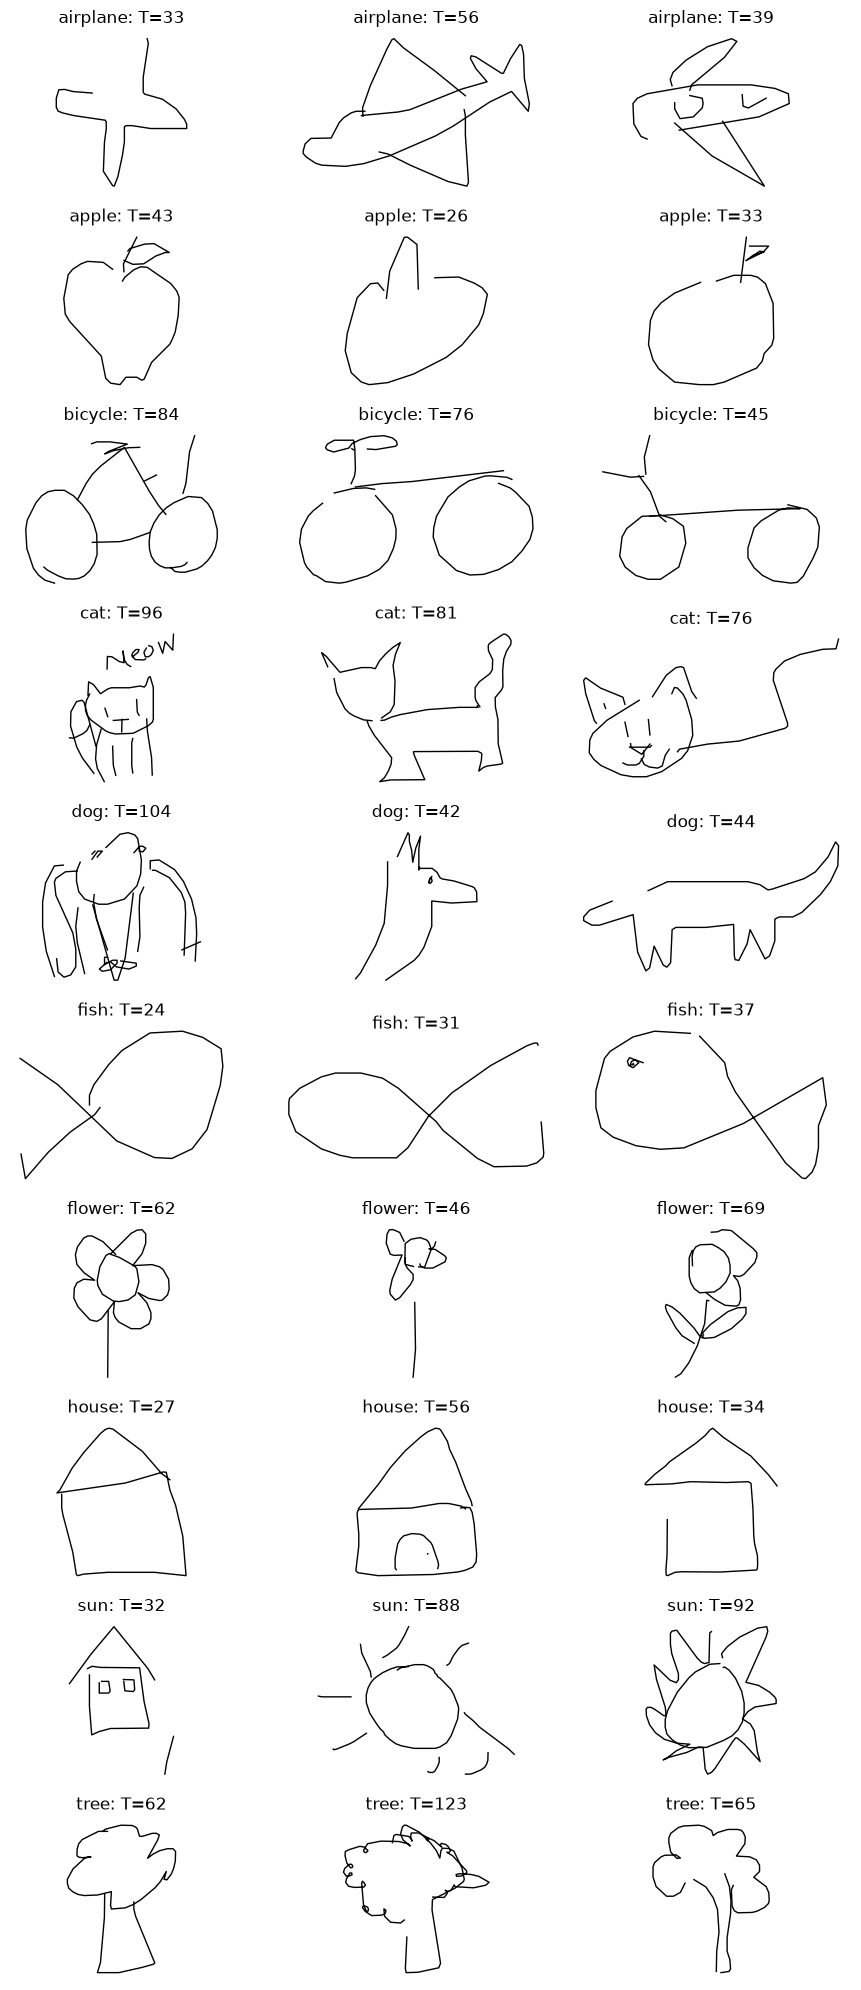

cat {'min': 37.0, 'median': 65.0, 'p90': 101.0, 'p95': 112.0, 'p99': 125.0, 'max': 129.0}


dog {'min': 40.0, 'median': 72.0, 'p90': 107.0, 'p95': 117.0, 'p99': 129.0, 'max': 133.0}


house {'min': 18.0, 'median': 32.0, 'p90': 50.0, 'p95': 57.0, 'p99': 66.0, 'max': 69.0}


tree {'min': 35.0, 'median': 63.0, 'p90': 107.0, 'p95': 130.0, 'p99': 164.0, 'max': 176.0}


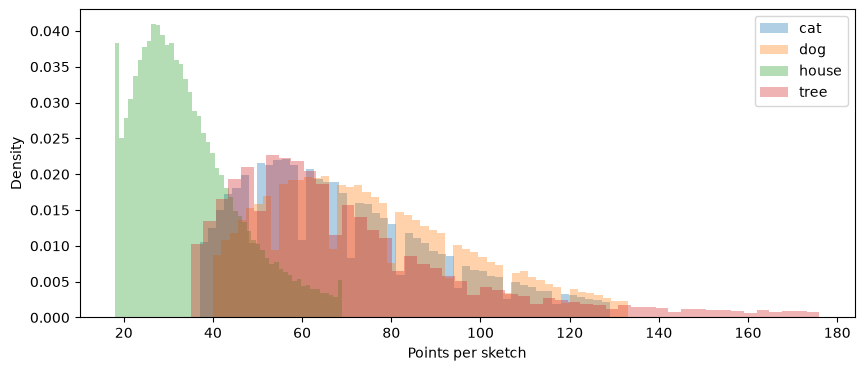

,category,split,samples,median_length
0,The Eiffel Tower,train,118210,33.0
1,The Eiffel Tower,valid,2500,32.0
2,The Eiffel Tower,test,2500,33.0
3,The Great Wall of China,train,170161,53.0
4,The Great Wall of China,valid,2500,54.0
5,The Great Wall of China,test,2500,54.0
6,The Mona Lisa,train,104644,76.0
7,The Mona Lisa,valid,2500,76.0
8,The Mona Lisa,test,2500,75.0


Totals: {'test': 862500, 'train': 43988874, 'valid': 862500}


In [7]:
def load_shard(category, split="train"):
    with np.load(OUTPUT / category / f"{split}.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}

def get_sample(shard, index):
    start, stop = shard["offsets"][index:index + 2]
    return shard["points"][start:stop], int(shard["labels"][index]), str(shard["ids"][index])

preview_categories = ["airplane", "apple", "bicycle", "cat", "dog", "fish", "flower", "house", "sun", "tree"]
fig, axes = plt.subplots(len(preview_categories), 3, figsize=(9, 20), squeeze=False)
for row, category in enumerate(preview_categories):
    shard = load_shard(category)
    for column in range(3):
        sequence, label, identifier = get_sample(shard, column)
        draw_sketch(axes[row, column], sequence)
        axes[row, column].set_title(f"{category}: T={len(sequence)}")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
for category in ["cat", "dog", "house", "tree"]:
    shard = load_shard(category)
    lengths = np.diff(shard["offsets"])
    ax.hist(lengths, bins=50, density=True, alpha=0.35, label=category)
    print(category, manifest["statistics"][category]["train"]["length_percentiles"])
ax.set_xlabel("Points per sketch")
ax.set_ylabel("Density")
ax.legend()
plt.show()

summary = pd.DataFrame([{ "category": category, "split": split, "samples": statistics[category][split]["samples"],
                          "median_length": statistics[category][split]["length_percentiles"]["median"]}
                         for category in categories for split in SPLITS])
display(summary.head(9))
print("Totals:", summary.groupby("split")["samples"].sum().to_dict())

## 6. Prepare a mixed-class batch
Pad only to the longest sketch in the batch. Return float32 inputs `[B,T,3]`,
int64 lengths and labels `[B]`, and a boolean mask `[B,T]` with True for real
points. An RNN must use sequence lengths or masked pooling to exclude padding.
Convert these arrays to tensors in the framework chosen by the model team.
Cross-entropy receives class logits and the integer labels.

**Why pad a batch:** lengths 3 and 2 become a tensor `[2, 3, 3]`. The second
sketch receives one zero row, but its length stays 2 and its mask is
`[True, True, False]`. Packing or masking tells the RNN that the padded row
is not part of the drawing. This step is temporary model-input preparation.

inputs (32, 109, 3) float32
lengths (32,) int64
labels (32,) int64
mask (32, 109) bool


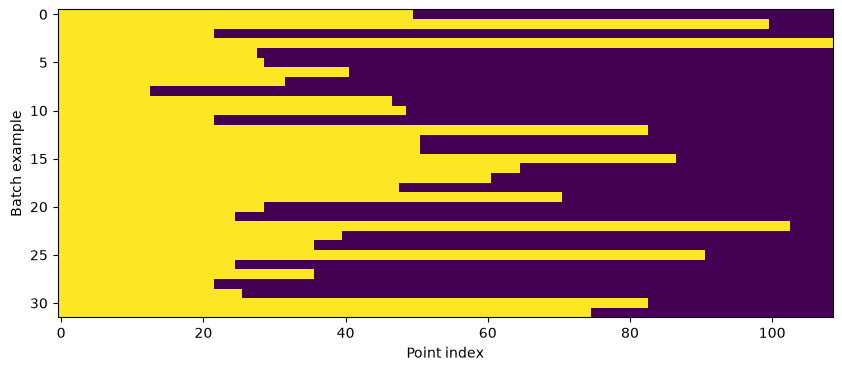

PyTorch input: torch.Size([32, 109, 3]) torch.float32


In [8]:
def collate_batch(samples):
    if not samples:
        raise ValueError("Empty batch")
    lengths = np.asarray([len(sequence) for sequence, _, _ in samples], dtype=np.int64)
    inputs = np.zeros((len(samples), int(lengths.max()), 3), dtype=np.float32)
    for row, (sequence, _, _) in enumerate(samples):
        inputs[row, :len(sequence)] = sequence
    return {"inputs": inputs, "lengths": lengths,
            "labels": np.asarray([label for _, label, _ in samples], dtype=np.int64),
            "mask": np.arange(inputs.shape[1])[None, :] < lengths[:, None],
            "ids": [identifier for _, _, identifier in samples]}

rng = np.random.default_rng(21)
samples = []
for category in rng.choice(categories, size=8, replace=False):
    shard = load_shard(str(category))
    for index in rng.choice(len(shard["labels"]), size=4, replace=False):
        samples.append(get_sample(shard, int(index)))
rng.shuffle(samples)
batch = collate_batch(samples)
for key in ["inputs", "lengths", "labels", "mask"]:
    print(key, batch[key].shape, batch[key].dtype)
assert np.array_equal(batch["mask"].sum(axis=1), batch["lengths"])
assert np.all(batch["inputs"][~batch["mask"]] == 0)
for row, (sequence, label, _) in enumerate(samples):
    assert np.array_equal(batch["inputs"][row, :len(sequence)], sequence)
    assert batch["labels"][row] == label
fig, ax = plt.subplots(figsize=(10, 4))
ax.imshow(batch["mask"], aspect="auto", interpolation="nearest")
ax.set_xlabel("Point index")
ax.set_ylabel("Batch example")
plt.show()

torch_batch = {key: torch.from_numpy(batch[key]) for key in ("inputs", "lengths", "labels", "mask")}
print("PyTorch input:", torch_batch["inputs"].shape, torch_batch["inputs"].dtype)
assert torch_batch["labels"].dtype == torch.int64
assert torch.equal(torch_batch["mask"].sum(dim=1), torch_batch["lengths"])

## 7. Check normalization against a source sketch
Verify coordinate scaling, unchanged pen flags, source identity, and the output
file's exact sequence length. This catches accidental double normalization or
stroke-boundary changes.

In [9]:
shard = load_shard("cat")
normalized, label, identifier = get_sample(shard, 0)
with np.load(archive_path("cat"), allow_pickle=True, encoding="latin1") as archive:
    original = np.asarray(archive["train"][0], dtype=np.float32)
unit_scaled = uniform_scale(original, np.array([0, len(original)], dtype=np.int64))
assert np.allclose(normalized[:, :2], unit_scaled[:, :2] / scale, rtol=1e-5, atol=1e-6)
reconstructed = np.cumsum(normalized[:, :2] * scale, axis=0, dtype=np.float64)
assert np.isclose(np.ptp(reconstructed, axis=0).max(), 1.0, atol=1e-5)
assert np.array_equal(normalized[:, 2], original[:, 2])
assert label == class_to_index["cat"]
assert identifier == f"cat/{version}/train/0"
assert len(normalized) == len(original)
print("Source identity, scaling, lengths, labels, and pen flags verified.")
print("Final dataset counts:", manifest["split_counts"])

Source identity, scaling, lengths, labels, and pen flags verified.
Final dataset counts: {'train': 43988874, 'valid': 862500, 'test': 862500}
